In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, precision_recall_curve)
from sklearn.preprocessing import LabelEncoder
import joblib

# Set random seed for reproducibility
np.random.seed(42)

# Load dataset
print("Loading dataset...")
df = pd.read_excel(r'D:\Thesis\Main\Data\GW table\Dataset_binary11.xlsx')

# Display basic info
print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nClass distribution:\n{df['Recharge_Class'].value_counts()}")
print(f"\nMissing values:\n{df.isnull().sum()}")

# Define features and target
feature_cols = ['Rainfall', 'Soil', 'Geology', 'DEM', 'Drainage_Density',
                'Slope', 'Lineament_Density', 'LULC', 'TWI']
target_col = 'Recharge_Class'

X = df[feature_cols].values
y = df[target_col].values

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

Loading dataset...
Dataset shape: (51, 10)

Columns: ['Lineament_Density', 'Rainfall', 'TWI', 'Slope', 'DEM', 'Drainage_Density', 'LULC', 'Soil', 'Geology', 'Recharge_Class']

Class distribution:
Recharge_Class
1    37
0    14
Name: count, dtype: int64

Missing values:
Lineament_Density    0
Rainfall             0
TWI                  0
Slope                0
DEM                  0
Drainage_Density     0
LULC                 0
Soil                 0
Geology              0
Recharge_Class       0
dtype: int64

Feature matrix shape: (51, 9)
Target vector shape: (51,)


In [2]:
# Stratified split (maintains class proportions)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")

print(f"\nTrain class distribution:\n{pd.Series(y_train).value_counts()}")
print(f"\nTest class distribution:\n{pd.Series(y_test).value_counts()}")



Train set size: 40
Test set size: 11

Train class distribution:
1    29
0    11
Name: count, dtype: int64

Test class distribution:
1    8
0    3
Name: count, dtype: int64


In [3]:
rf_default = RandomForestClassifier(
    n_estimators=90,
    max_depth=10,
    min_samples_split=24,
    min_samples_leaf=14,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train model
rf_default.fit(X_train, y_train)

print(f"\n✓ Training completed!")
print(f"OOB Score: {rf_default.oob_score_:.4f}")

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done  90 out of  90 | elapsed:    0.1s finished



✓ Training completed!
OOB Score: 0.6250


In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import numpy as np

# ------------------------------
# Predictions
# ------------------------------
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)
y_pred_proba_test = rf_default.predict_proba(X_test)

# ------------------------------
# Accuracy
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# ------------------------------
# Classification Report (Binary)
# ------------------------------
print("\n" + "="*80)
print("CLASSIFICATION REPORT (Test Set)")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],  # ✅ ONLY TWO
    zero_division=0
))

# ------------------------------
# Confusion Matrix
# ------------------------------
cm = confusion_matrix(y_test, y_pred_test)
print("\nConfusion Matrix:")
print(cm)

# ------------------------------
# ROC AUC (Binary)
# ------------------------------
roc_auc = roc_auc_score(y_test, y_pred_proba_test[:, 1])
print(f"\nROC AUC Score: {roc_auc:.4f}")



Training Accuracy: 0.9750
Test Accuracy: 0.9091

CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

         Low       1.00      0.67      0.80         3
        High       0.89      1.00      0.94         8

    accuracy                           0.91        11
   macro avg       0.94      0.83      0.87        11
weighted avg       0.92      0.91      0.90        11


Confusion Matrix:
[[2 1]
 [0 8]]

ROC AUC Score: 0.9583


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done  90 out of  90 | elapsed:    0.0s finished



Training Accuracy: 0.9750
Test Accuracy: 0.9091

CLASSIFICATION REPORT (Test Set)
              precision    recall  f1-score   support

         Low       1.00      0.67      0.80         3
        High       0.89      1.00      0.94         8

    accuracy                           0.91        11
   macro avg       0.94      0.83      0.87        11
weighted avg       0.92      0.91      0.90        11


Confusion Matrix (Test Set):
[[2 1]
 [0 8]]


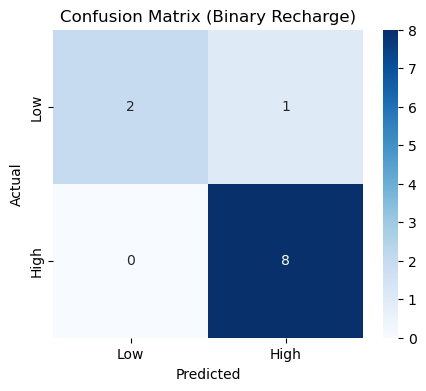


ROC AUC Score: 0.9583


In [5]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ------------------------------
# Predictions
# ------------------------------
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)
y_pred_proba_test = rf_default.predict_proba(X_test)

# ------------------------------
# Accuracy
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# ------------------------------
# Classification Report (Binary)
# ------------------------------
print("\n" + "="*80)
print("CLASSIFICATION REPORT (Test Set)")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],  # Binary labels
    zero_division=0
))

# ------------------------------
# Confusion Matrix (Binary)
# ------------------------------
cm = confusion_matrix(y_test, y_pred_test)
cm_labels = ['Low', 'High']

print("\nConfusion Matrix (Test Set):")
print(cm)

# Heatmap
plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=cm_labels,
    yticklabels=cm_labels,
    cmap='Blues'
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Binary Recharge)')
plt.show()

# ------------------------------

# ROC AUC Score (Binary)
# ------------------------------
roc_auc = roc_auc_score(y_test, y_pred_proba_test[:, 1])
print(f"\nROC AUC Score: {roc_auc:.4f}")


In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 2️⃣ Setup Stratified K-Fold
# 5 folds is standard for small datasets
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3️⃣ Run Cross-Validation
scores = cross_val_score(
    rf_default,
    X,
    y,
    cv=skf,
    scoring='accuracy'
)

print(f"Accuracy per fold: {scores}")
print(f"Average Accuracy: {scores.mean():.4f}")
print(f"Standard Deviation: {scores.std():.4f}")


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    0.3s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Do

Accuracy per fold: [0.63636364 1.         1.         0.8        0.8       ]
Average Accuracy: 0.8473
Standard Deviation: 0.1383


[Parallel(n_jobs=-1)]: Done 176 tasks      | elapsed:    0.2s
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:    0.2s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 176 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 200 out of 200 | elapsed:    0.0s finished


In [17]:
from sklearn.metrics import accuracy_score, r2_score, mean_squared_error
import numpy as np

# ------------------------------
# Predictions
# ------------------------------
y_pred_train = rf_default.predict(X_train)
y_pred_test = rf_default.predict(X_test)

# ------------------------------
# Accuracy
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

# ------------------------------
# RMSE (classification)
# ------------------------------
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))

# ------------------------------
# R² (optional, not standard for classification)
# ------------------------------
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

print(f"Train Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Train RMSE: {rmse_train:.4f}")
print(f"Test RMSE: {rmse_test:.4f}")
print(f"Train R²: {r2_train:.4f}")
print(f"Test R²: {r2_test:.4f}")


Train Accuracy: 0.8500
Test Accuracy: 0.9091
Train RMSE: 0.3873
Test RMSE: 0.3015
Train R²: 0.2476
Test R²: 0.5417


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished


In [18]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, mean_squared_error, r2_score
import numpy as np

# ------------------------------
# 1. Custom Prediction Threshold
# ------------------------------
# Instead of default 0.5, we lower the bar for "Low" (Class 0)
# We predict "High" only if probability is > 0.6
y_probs_train = rf_default.predict_proba(X_train)[:, 1]
y_probs_test = rf_default.predict_proba(X_test)[:, 1]

threshold = 0.55 # 👈 ADJUST THIS: Higher value makes the model more likely to predict "Low"
y_pred_train = (y_probs_train > threshold).astype(int)
y_pred_test = (y_probs_test > threshold).astype(int)

# ------------------------------
# 2. Accuracy & Regression Metrics
# ------------------------------
train_accuracy = accuracy_score(y_train, y_pred_train)
test_accuracy = accuracy_score(y_test, y_pred_test)

# RMSE and R2 (Treating classes as 0 and 1)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2 = r2_score(y_test, y_pred_test)

print(f"\nTraining Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")

# ------------------------------
# 3. Classification Report
# ------------------------------
print("\n" + "="*80)
print(f"CLASSIFICATION REPORT (Test Set) - Threshold: {threshold}")
print("="*80)
print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Low', 'High'],
    zero_division=0
))

# ------------------------------
# 4. Confusion Matrix
# ------------------------------
cm = confusion_matrix(y_test, y_pred_test)
print("\nConfusion Matrix:")
print(cm)

# ------------------------------
# 5. ROC AUC
# ------------------------------
roc_auc = roc_auc_score(y_test, y_probs_test)
print(f"\nROC AUC Score: {roc_auc:.4f}")


Training Accuracy: 0.8000
Test Accuracy: 0.9091
RMSE: 0.3015
R2 Score: 0.5417

CLASSIFICATION REPORT (Test Set) - Threshold: 0.55
              precision    recall  f1-score   support

         Low       0.75      1.00      0.86         3
        High       1.00      0.88      0.93         8

    accuracy                           0.91        11
   macro avg       0.88      0.94      0.90        11
weighted avg       0.93      0.91      0.91        11


Confusion Matrix:
[[3 0]
 [1 7]]

ROC AUC Score: 0.9167


[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished
[Parallel(n_jobs=12)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=12)]: Done 100 out of 100 | elapsed:    0.0s finished


In [9]:
from sklearn.model_selection import GridSearchCV

print("\n" + "="*80)
print("HYPERPARAMETER TUNING - Grid Search")
print("="*80)

# Define parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [15, 20, 25, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# Initialize Grid Search
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(bootstrap=True, oob_score=True, 
                                    class_weight='balanced', random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=5,  # 5-fold cross-validation
    scoring='accuracy',
    verbose=2,
    n_jobs=-1
)

# Fit Grid Search
print("\nRunning Grid Search (this may take several minutes)...")
rf_grid.fit(X_train, y_train)

# Best parameters
print("\n" + "="*80)
print("BEST HYPERPARAMETERS")
print("="*80)
print(rf_grid.best_params_)
print(f"\nBest CV Score: {rf_grid.best_score_:.4f}")

# Evaluate best model
best_rf = rf_grid.best_estimator_
y_pred_best = best_rf.predict(X_test)
best_accuracy = accuracy_score(y_test, y_pred_best)
print(f"Test Accuracy (Best Model): {best_accuracy:.4f}")
print(f"OOB Score (Best Model): {best_rf.oob_score_:.4f}")

# Save best model
joblib.dump(best_rf, r'D:\Thesis\Main\Models\Random Forest\RF_Best_Model.pkl')
print("\n✓ Best model saved: RF_Best_Model.pkl")


HYPERPARAMETER TUNING - Grid Search

Running Grid Search (this may take several minutes)...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits

BEST HYPERPARAMETERS
{'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best CV Score: 0.9250
Test Accuracy (Best Model): 0.9091
OOB Score (Best Model): 0.8750

✓ Best model saved: RF_Best_Model.pkl


In [10]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

print("\n" + "="*80)
print("HYPERPARAMETER TUNING - Randomized Search")
print("="*80)

# Define parameter distributions
param_distributions = {
    'n_estimators': randint(100, 500),
    'max_depth': [10, 15, 20, 25, 30, None],
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
    'max_features': ['sqrt', 'log2', 0.3, 0.5]
}

# Initialize Randomized Search
rf_random = RandomizedSearchCV(
    estimator=RandomForestClassifier(bootstrap=True, oob_score=True,
                                    class_weight='balanced', random_state=42, n_jobs=-1),
    param_distributions=param_distributions,
    n_iter=50,  # Number of parameter settings sampled
    cv=5,
    scoring='accuracy',
    verbose=2,
    random_state=42,
    n_jobs=-1
)

# Fit Randomized Search
print("\nRunning Randomized Search...")
rf_random.fit(X_train, y_train)

# Best parameters
print("\n" + "="*80)
print("BEST HYPERPARAMETERS (Randomized Search)")
print("="*80)
print(rf_random.best_params_)
print(f"\nBest CV Score: {rf_random.best_score_:.4f}")

# Evaluate
best_rf_random = rf_random.best_estimator_
y_pred_random = best_rf_random.predict(X_test)
random_accuracy = accuracy_score(y_test, y_pred_random)
print(f"Test Accuracy: {random_accuracy:.4f}")
print(f"OOB Score: {best_rf_random.oob_score_:.4f}")


HYPERPARAMETER TUNING - Randomized Search

Running Randomized Search...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

BEST HYPERPARAMETERS (Randomized Search)
{'max_depth': 20, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 149}

Best CV Score: 0.9250
Test Accuracy: 0.9091
OOB Score: 0.8500


In [7]:
# ==============================================================
# 1. IMPORT LIBRARIES
# ==============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_squared_error,
    r2_score
)

import joblib

np.random.seed(42)


# ==============================================================
# 4. STRATIFIED TRAIN–TEST SPLIT
# ==============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n" + "="*80)
print("TRAIN–TEST SPLIT SUMMARY")
print("="*80)
print(f"Train set size: {X_train.shape[0]}")
print(f"Test set size : {X_test.shape[0]}")
print("\nTrain class distribution:\n", pd.Series(y_train).value_counts())
print("\nTest class distribution:\n", pd.Series(y_test).value_counts())

# ==============================================================
# 5. HYPERPARAMETER TUNING (GRID SEARCH)
# ==============================================================

print("\n" + "="*80)
print("HYPERPARAMETER TUNING – GRID SEARCH")
print("="*80)

param_grid = {
    'n_estimators': [100, 200, 300,400,500],
    'max_depth': [15, 20, 25,30, None],
    'min_samples_split': [ 5,10,15,20,25],
    'min_samples_leaf': [ 2,4,8,10,15],
    'max_features': ['sqrt', 'log2']
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(
        bootstrap=True,
        oob_score=True,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    verbose=2,
    n_jobs=-1
)

print("\nRunning Grid Search...")
rf_grid.fit(X_train, y_train)

print("\n" + "="*80)
print("BEST HYPERPARAMETERS")
print("="*80)
print(rf_grid.best_params_)
print(f"\nBest CV Accuracy: {rf_grid.best_score_:.4f}")

# ==============================================================
# 6. BEST MODEL EVALUATION
# ==============================================================

best_rf = rf_grid.best_estimator_

# Predictions
y_train_pred = best_rf.predict(X_train)
y_test_pred = best_rf.predict(X_test)

# ---------- TRAIN METRICS ----------
train_accuracy = accuracy_score(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

# ---------- TEST METRICS ----------
test_accuracy = accuracy_score(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

# ==============================================================
# 7. PERFORMANCE SUMMARY
# ==============================================================

print("\n" + "="*80)
print("MODEL PERFORMANCE SUMMARY")
print("="*80)

print("\nTRAIN SET PERFORMANCE")
print(f"Accuracy : {train_accuracy:.4f}")
print(f"RMSE     : {train_rmse:.4f}")
print(f"R² Score : {train_r2:.4f}")

print("\nTEST SET PERFORMANCE")
print(f"Accuracy : {test_accuracy:.4f}")
print(f"RMSE     : {test_rmse:.4f}")
print(f"R² Score : {test_r2:.4f}")

print(f"\nOOB Score: {best_rf.oob_score_:.4f}")

# ==============================================================
# 8. CLASSIFICATION REPORT & CONFUSION MATRIX
# ==============================================================

print("\n" + "="*80)
print("CLASSIFICATION REPORT (TEST SET)")
print("="*80)
print(classification_report(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

# ==============================================================
# 9. SAVE BEST MODEL
# ==============================================================

# model_path = r'D:\Thesis\Main\Models\Random Forest\RF_Best_Model1.pkl'
# joblib.dump(best_rf, model_path)

# print("\n✓ Best model saved successfully!")
# print(f"Model path: {model_path}")



TRAIN–TEST SPLIT SUMMARY
Train set size: 40
Test set size : 11

Train class distribution:
 1    24
0    16
Name: count, dtype: int64

Test class distribution:
 1    6
0    5
Name: count, dtype: int64

HYPERPARAMETER TUNING – GRID SEARCH

Running Grid Search...
Fitting 5 folds for each of 1250 candidates, totalling 6250 fits

BEST HYPERPARAMETERS
{'max_depth': 15, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 500}

Best CV Accuracy: 0.7500

MODEL PERFORMANCE SUMMARY

TRAIN SET PERFORMANCE
Accuracy : 0.9750
RMSE     : 0.1581
R² Score : 0.8958

TEST SET PERFORMANCE
Accuracy : 0.6364
RMSE     : 0.6030
R² Score : -0.4667

OOB Score: 0.7250

CLASSIFICATION REPORT (TEST SET)
              precision    recall  f1-score   support

           0       0.60      0.60      0.60         5
           1       0.67      0.67      0.67         6

    accuracy                           0.64        11
   macro avg       0.63      0.63      0.63        11
weighted 

In [6]:
from sklearn.model_selection import cross_validate

print("\n" + "="*80)
print("K-FOLD CROSS-VALIDATION (K=5)")
print("="*80)

# Define model
rf_cv = RandomForestClassifier(
    n_estimators=90,
    max_depth=10,
    min_samples_split=24,
    min_samples_leaf=14,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Perform cross-validation
cv_results = cross_validate(
    rf_cv, X, y,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring=['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted'],
    return_train_score=True,
    n_jobs=-1
)

# Display results
print("\nCross-Validation Results (5-Fold):")
print(f"  Mean Train Accuracy: {cv_results['train_accuracy'].mean():.4f} ± {cv_results['train_accuracy'].std():.4f}")
print(f"  Mean Test Accuracy:  {cv_results['test_accuracy'].mean():.4f} ± {cv_results['test_accuracy'].std():.4f}")
print(f"  Mean Precision:      {cv_results['test_precision_weighted'].mean():.4f} ± {cv_results['test_precision_weighted'].std():.4f}")
print(f"  Mean Recall:         {cv_results['test_recall_weighted'].mean():.4f} ± {cv_results['test_recall_weighted'].std():.4f}")
print(f"  Mean F1-Score:       {cv_results['test_f1_weighted'].mean():.4f} ± {cv_results['test_f1_weighted'].std():.4f}")

# # Save CV results
# cv_df = pd.DataFrame(cv_results)
# cv_df.to_csv( r'D:\Thesis\Main\Models\Random Forest\RF_Best_Model_90,90.csv', index=False)
# print("\n✓ CV results saved: RF_CrossValidation_Results.csv")


K-FOLD CROSS-VALIDATION (K=5)

Cross-Validation Results (5-Fold):
  Mean Train Accuracy: 0.8918 ± 0.0347
  Mean Test Accuracy:  0.8400 ± 0.1200
  Mean Precision:      0.8415 ± 0.1801
  Mean Recall:         0.8400 ± 0.1200
  Mean F1-Score:       0.8206 ± 0.1498


In [8]:
# Train final model on full dataset
print("\n" + "="*80)
print("TRAINING FINAL RANDOM FOREST MODEL")
print("="*80)

rf_final = RandomForestClassifier(
    n_estimators=90,
    max_depth=10,
    min_samples_split=24,
    min_samples_leaf=14,
    max_features='sqrt',
    bootstrap=True,
    oob_score=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_final.fit(X, y)

print(f"\n✓ Final model trained!")
# print(f"OOB Score: {rf_final.oob_score_:.4f}")

# Save model
joblib.dump(rf_final, r'D:\Thesis\Main\Models\Random Forest\New Final\RF_Final_Model11.pkl')
print("✓ Final model saved: RF_Final_Model11.pkl")

# Save feature names for later use
joblib.dump(feature_cols, r'D:\Thesis\Main\Models\Random Forest\New Final\RF_Final_Model_Features_name11.pkl')
print("✓ Feature names saved: feature_names11.pkl")


TRAINING FINAL RANDOM FOREST MODEL


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    0.0s
[Parallel(n_jobs=-1)]: Done  90 out of  90 | elapsed:    0.1s finished



✓ Final model trained!
OOB Score: 0.9412
✓ Final model saved: RF_Final_Model11.pkl
✓ Feature names saved: feature_names11.pkl


In [20]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import numpy as np

# Use your NumPy arrays X, y
rf_default = RandomForestClassifier(random_state=42)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
fold_accuracies = []

for train_index, test_index in skf.split(X, y):
    # Split data (NumPy indexing, no iloc)
    X_train_fold, X_test_fold = X[train_index], X[test_index]
    y_train_fold, y_test_fold = y[train_index], y[test_index]
    
    # Train model
    rf_default.fit(X_train_fold, y_train_fold)
    
    # Get probabilities for class 1
    y_probs_fold = rf_default.predict_proba(X_test_fold)[:, 1]
    
    # Apply threshold
    y_pred_fold = (y_probs_fold >= 0.3).astype(int)
    
    # Accuracy
    acc = accuracy_score(y_test_fold, y_pred_fold)
    fold_accuracies.append(acc)

print(f"Accuracy per fold : {np.array(fold_accuracies)}")
print(f"Average Accuracy: {np.mean(fold_accuracies):.4f}")
print(f"Standard Deviation: {np.std(fold_accuracies):.4f}")


Accuracy per fold : [1.  0.9 0.8 1.  0.9]
Average Accuracy: 0.9200
Standard Deviation: 0.0748


In [19]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ============================================================
# SETTINGS
# ============================================================

thresholds = np.arange(0.20, 0.6, 0.01)

rf_model = RandomForestClassifier(
    n_estimators=90,
    max_depth=10,
    min_samples_split=24,
    min_samples_leaf=14,
    max_features='sqrt',
    bootstrap=True,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ============================================================
# THRESHOLD OPTIMIZATION USING STRATIFIED K-FOLD
# ============================================================

results = []

for threshold in thresholds:
    fold_acc = []
    fold_prec = []
    fold_rec = []
    fold_f1 = []

    for train_idx, test_idx in skf.split(X, y):
        X_train_fold, X_test_fold = X[train_idx], X[test_idx]
        y_train_fold, y_test_fold = y[train_idx], y[test_idx]

        rf_model.fit(X_train_fold, y_train_fold)

        # Probability for positive class (1)
        y_prob = rf_model.predict_proba(X_test_fold)[:, 1]

        # Apply threshold
        y_pred = (y_prob >= threshold).astype(int)

        fold_acc.append(accuracy_score(y_test_fold, y_pred))
        fold_prec.append(precision_score(y_test_fold, y_pred, zero_division=0))
        fold_rec.append(recall_score(y_test_fold, y_pred, zero_division=0))
        fold_f1.append(f1_score(y_test_fold, y_pred, zero_division=0))

    results.append({
        'threshold': threshold,
        'mean_accuracy': np.mean(fold_acc),
        'std_accuracy': np.std(fold_acc),
        'mean_precision': np.mean(fold_prec),
        'mean_recall': np.mean(fold_rec),
        'mean_f1': np.mean(fold_f1)
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# ============================================================
# SELECT BEST THRESHOLD
# ============================================================

best_row = results_df.loc[results_df['mean_accuracy'].idxmax()]

print("\n" + "="*80)
print("BEST THRESHOLD (BASED ON CV ACCURACY)")
print("="*80)
print(best_row)

# Save results
results_df.to_csv(
    r'D:\Thesis\Main\Models\Random Forest\New Final\RF_Threshold_Optimization_Final11.csv',
    index=False
)

print("\n✓ Threshold optimization results saved")



BEST THRESHOLD (BASED ON CV ACCURACY)
threshold         0.500000
mean_accuracy     0.840000
std_accuracy      0.120000
mean_precision    0.915000
mean_recall       0.896429
mean_f1           0.889834
Name: 30, dtype: float64

✓ Threshold optimization results saved


In [27]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# =====================================================
# PARAMETER RANGES (STEPPED, FEASIBLE)
# =====================================================

n_estimators_range = range(50, 1001, 50)
max_depth_range = range(5, 31, 5)
min_split_range = range(5, 31, 5)
min_leaf_range = range(5, 31, 5)

thresholds = np.arange(0.30, 0.71, 0.05)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

# =====================================================
# MANUAL GRID + THRESHOLD OPTIMIZATION
# =====================================================

for n_est in n_estimators_range:
    for depth in max_depth_range:
        for min_split in min_split_range:
            for min_leaf in min_leaf_range:

                threshold_results = []

                for threshold in thresholds:
                    acc_scores = []
                    f1_scores = []

                    for train_idx, test_idx in skf.split(X, y):
                        X_train_fold, X_test_fold = X[train_idx], X[test_idx]
                        y_train_fold, y_test_fold = y[train_idx], y[test_idx]

                        model = RandomForestClassifier(
                            n_estimators=n_est,
                            max_depth=depth,
                            min_samples_split=min_split,
                            min_samples_leaf=min_leaf,
                            max_features='sqrt',
                            class_weight='balanced',
                            random_state=42,
                            n_jobs=-1
                        )

                        model.fit(X_train_fold, y_train_fold)

                        y_prob = model.predict_proba(X_test_fold)[:, 1]
                        y_pred = (y_prob >= threshold).astype(int)

                        acc_scores.append(accuracy_score(y_test_fold, y_pred))
                        f1_scores.append(f1_score(y_test_fold, y_pred, zero_division=0))

                    threshold_results.append({
                        'threshold': threshold,
                        'mean_accuracy': np.mean(acc_scores),
                        'mean_f1': np.mean(f1_scores)
                    })

                best_threshold = max(
                    threshold_results,
                    key=lambda x: x['mean_accuracy']
                )

                results.append({
                    'n_estimators': n_est,
                    'max_depth': depth,
                    'min_samples_split': min_split,
                    'min_samples_leaf': min_leaf,
                    'best_threshold': best_threshold['threshold'],
                    'cv_accuracy': best_threshold['mean_accuracy'],
                    'cv_f1': best_threshold['mean_f1']
                })

# =====================================================
# RESULTS SUMMARY
# =====================================================

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by='cv_accuracy', ascending=False)

print("\nTOP 5 MODELS:")
print(results_df.head())

# results_df.to_csv(
#     r'D:\Thesis\Main\Models\Random Forest\RF_Hyperparameter_Threshold_Optimization.csv',
#     index=False
# )

# print("\n✓ Hyperparameter + threshold optimization completed")


TypeError: 'int' object is not iterable